In [1]:
!mamba install pandas

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 1.790 seconds
  Name    Version  Build                Channel
-------------------------------------------------------------
+ pandas  3.1.0    np23py313h124dbc7_0  emscripten-forge-4x
- pip     26.2.2   pyh145f28c_0         conda-forge


In [4]:
import pandas as pd
import numpy as np
import os

In [8]:
orders_files = [
    "orders_2024_01.csv",
    "orders_2024_02.csv",
    "orders_2024_03.csv"
]

orders_list = []

for file in orders_files:
    df = pd.read_csv(file)
    orders_list.append(df)

df_orders = pd.concat(orders_list, ignore_index=True)

print("Первые 5 строк таблицы:")
display(df_orders.head())

print("Информация о таблице:")
df_orders.info()

orders_list = []

for file in orders_files:
    df = pd.read_csv(file)
    orders_list.append(df)

df_orders = pd.concat(orders_list, ignore_index=True)

print("Первые 5 строк таблицы:")
display(df_orders.head())

print("Информация о таблице:")
df_orders.info()

Первые 5 строк таблицы:


,order_id,user_id,order_datetime,product_id,price,quantity,status
0,1,1044,2024-01-03 18:39:26,26,14038.15,1,refunded
1,2,1079,2024-01-03 17:45:43,16,9172.60,1,paid
2,3,1041,2024-01-06 22:46:38,25,9035.26,2,paid
3,4,1083,2024-01-08 21:03:51,9,15234.33,3,paid
4,5,1068,2024-01-03 23:26:53,24,4134.38,2,paid


Информация о таблице:
<class 'pandas.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   order_id        15000 non-null  int64  
 1   user_id         15000 non-null  int64  
 2   order_datetime  15000 non-null  str    
 3   product_id      15000 non-null  int64  
 4   price           15000 non-null  float64
 5   quantity        15000 non-null  int64  
 6   status          15000 non-null  str    
dtypes: float64(1), int64(4), str(2)
memory usage: 703.2 KB
Первые 5 строк таблицы:


,order_id,user_id,order_datetime,product_id,price,quantity,status
0,1,1044,2024-01-03 18:39:26,26,14038.15,1,refunded
1,2,1079,2024-01-03 17:45:43,16,9172.60,1,paid
2,3,1041,2024-01-06 22:46:38,25,9035.26,2,paid
3,4,1083,2024-01-08 21:03:51,9,15234.33,3,paid
4,5,1068,2024-01-03 23:26:53,24,4134.38,2,paid


Информация о таблице:
<class 'pandas.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   order_id        15000 non-null  int64  
 1   user_id         15000 non-null  int64  
 2   order_datetime  15000 non-null  str    
 3   product_id      15000 non-null  int64  
 4   price           15000 non-null  float64
 5   quantity        15000 non-null  int64  
 6   status          15000 non-null  str    
dtypes: float64(1), int64(4), str(2)
memory usage: 703.2 KB


In [9]:
df_orders["order_datetime"] = pd.to_datetime(
    df_orders["order_datetime"],
    errors="coerce"
)

df_orders = df_orders.dropna(subset=["order_datetime"])

df_orders["revenue"] = (
    df_orders["price"] * df_orders["quantity"]
)

print("Таблица после подготовки:")
display(df_orders.head())

Таблица после подготовки:


,order_id,user_id,order_datetime,product_id,price,quantity,status,revenue
0,1,1044,2024-01-03 18:39:26,26,14038.15,1,refunded,14038.15
1,2,1079,2024-01-03 17:45:43,16,9172.60,1,paid,9172.60
2,3,1041,2024-01-06 22:46:38,25,9035.26,2,paid,18070.52
3,4,1083,2024-01-08 21:03:51,9,15234.33,3,paid,45702.99
4,5,1068,2024-01-03 23:26:53,24,4134.38,2,paid,8268.76


In [10]:
daily_stats = (
    df_orders
    .groupby(df_orders["order_datetime"].dt.date)
    .agg(
        orders_count=("order_id", "nunique"),
        revenue=("revenue", "sum")
    )
)

daily_stats.index = pd.to_datetime(daily_stats.index)

daily_stats = daily_stats.asfreq("D", fill_value=0)

print("Дневная статистика заказов:")
display(daily_stats.head(15))

Дневная статистика заказов:


,orders_count,revenue
order_datetime,,
2024-01-01,164,4483590.00
2024-01-02,158,4095217.58
2024-01-03,168,4425023.45
2024-01-04,176,3747060.38
2024-01-05,176,4623480.03
2024-01-06,160,4517551.37
2024-01-07,160,3996399.29
2024-01-08,161,4189487.36
2024-01-09,175,4470895.51


In [11]:
daily_stats["revenue_7d_avg"] = (
    daily_stats["revenue"]
    .rolling(window=7, min_periods=1)
    .mean()
)

print("Таблица с 7-дневным скользящим средним:")
display(daily_stats.head(15))

Таблица с 7-дневным скользящим средним:


,orders_count,revenue,revenue_7d_avg
order_datetime,,,
2024-01-01,164,4483590.00,4.483590e+06
2024-01-02,158,4095217.58,4.289404e+06
2024-01-03,168,4425023.45,4.334610e+06
2024-01-04,176,3747060.38,4.187723e+06
2024-01-05,176,4623480.03,4.274874e+06
2024-01-06,160,4517551.37,4.315320e+06
2024-01-07,160,3996399.29,4.269760e+06
2024-01-08,161,4189487.36,4.227746e+06
2024-01-09,175,4470895.51,4.281414e+06


In [12]:
max_avg_day = daily_stats["revenue_7d_avg"].idxmax()

max_avg_value = daily_stats.loc[
    max_avg_day, "revenue_7d_avg"
]

print("День с максимальным 7-дневным скользящим средним:")
print(max_avg_day)

print("Максимальное скользящее среднее:")
print(round(max_avg_value, 2))

День с максимальным 7-дневным скользящим средним:
2024-02-28 00:00:00
Максимальное скользящее среднее:
4502246.96


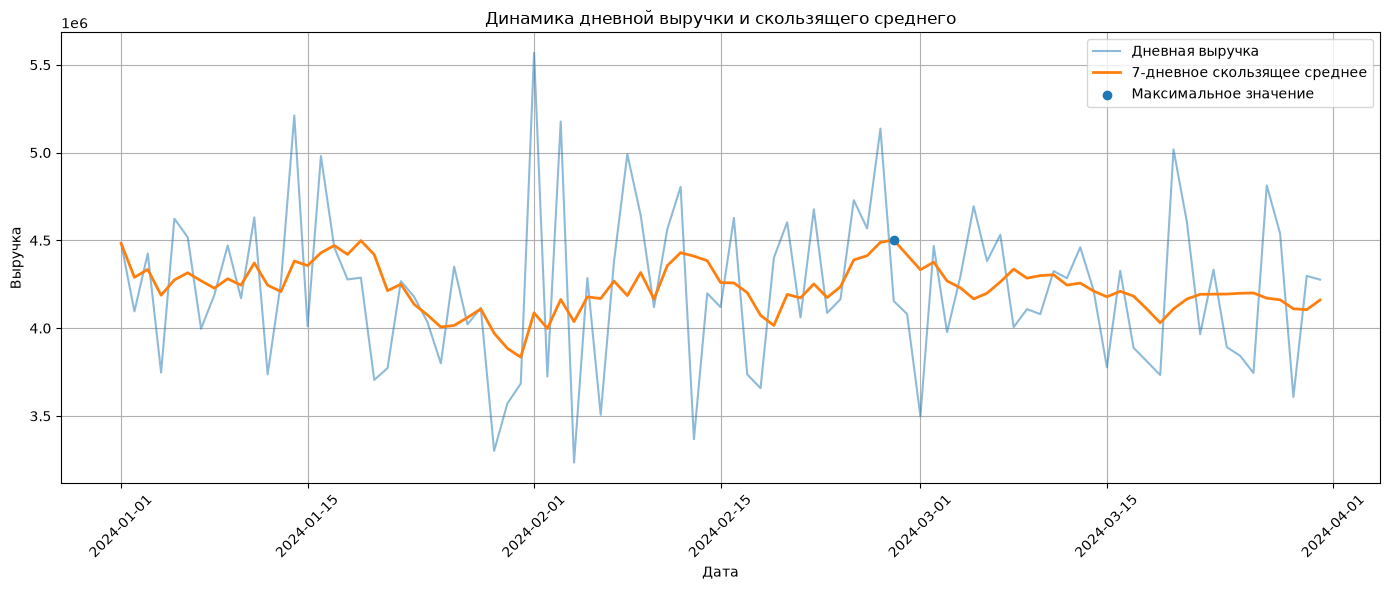

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    daily_stats.index,
    daily_stats["revenue"],
    label="Дневная выручка",
    alpha=0.5
)

plt.plot(
    daily_stats.index,
    daily_stats["revenue_7d_avg"],
    label="7-дневное скользящее среднее",
    linewidth=2
)

plt.scatter(
    max_avg_day,
    max_avg_value,
    label="Максимальное значение",
    zorder=5
)

plt.title("Динамика дневной выручки и скользящего среднего")
plt.xlabel("Дата")
plt.ylabel("Выручка")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [14]:
daily_stats.to_csv(
    "daily_revenue_analysis.csv",
    encoding="utf-8-sig"
)

print("Результат сохранён в daily_revenue_analysis.csv")

Результат сохранён в daily_revenue_analysis.csv
